# 03 - Baselines: decision tree, random forest and SVM

Goal: test the non-neural models with and without oversampling.

Reproduces: paper Sections 2.2.2, 2.2.3, 4.1.1, 4.1.2 and Tables 3, 5, 6, 8.

Needs: nothing except utils.py. Writes results/baselines.csv.

Expected run time: about 6 minutes with 10 repeats.

Status: executed

Repeats: 10 (the paper uses 100). Set N_REPEATS = 100 for final results.

## 1. Setup
We repeat everything N_REPEATS times with a new random split each time. We use seeds 0, 1, 2, and so on, so every model sees exactly the same splits.

In [1]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"  # Windows: set before the other imports

import math
import time

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from utils import (COLOURS, METRICS, SEED, compare_table, get_metrics, load_data, make_inputs,
                   paired_test, save_results, set_style, show_table, split_data)

N_REPEATS = 10  # paper uses 100
set_style()

df = load_data()
X, y = make_inputs(df)
n_cols = X.shape[1]
print("Input columns:", n_cols)

Input columns: 74


## 2. Choose the SVM settings once
An SVM (support vector machine) is a model that looks for the best boundary between the two classes. It has settings we must choose: C, and gamma for the RBF kernel. A kernel is a way of letting the boundary curve. As the paper says in Section 2.2.2, we choose these settings with a small grid search on one random train and validation split (seed 42), then reuse them for every repeat. We choose by validation F1, separately for each setting.

Note: this split overlaps the later test sets, so our choice may be very slightly too optimistic. As we read it, the paper's procedure has the same property.

In [2]:
linear_grid = [{"C": c} for c in [0.1, 1, 10]]
rbf_grid = [{"C": c, "gamma": g} for c in [1, 10] for g in [0.01, 0.1]]

def tune_svm(kernel, grid, oversample):
    """Return the grid values with the best validation F1."""
    X_tr, X_val, y_tr, y_val = split_data(X, y, seed=SEED, oversample=oversample)
    best_f1, best_params = -1, None
    for params in grid:
        model = SVC(kernel=kernel, **params).fit(X_tr, y_tr)
        f1 = get_metrics(y_val, model.predict(X_val))["f1"]
        if f1 > best_f1:
            best_f1, best_params = f1, params
    return best_params

svm_params = {}
for setting, oversample in [("imbalanced", False), ("oversampled", True)]:
    svm_params[setting] = {"linear": tune_svm("linear", linear_grid, oversample),
                           "rbf": tune_svm("rbf", rbf_grid, oversample)}
    print(setting, svm_params[setting])

imbalanced {'linear': {'C': 0.1}, 'rbf': {'C': 1, 'gamma': 0.1}}


oversampled {'linear': {'C': 0.1}, 'rbf': {'C': 1, 'gamma': 0.01}}


The search chose C = 0.1 for the linear kernel in both settings. For RBF it chose C = 1, with gamma = 0.1 on imbalanced data and gamma = 0.01 on oversampled data.

## 3. Define the models
Deviation from the paper: the paper uses C4.5, a type of decision tree. Our library, sklearn, builds CART-style trees, so DecisionTreeClassifier(criterion="entropy", ccp_alpha=0.001) only approximates C4.5. It uses the same information measure and it prunes after growing, but it makes only two-way splits and prunes by a different rule.

The random forest, a vote among many trees, follows the paper: 100 trees, max_features = ceil(log2(M)) and bags of size N. With our 74 columns this gives max_features = 7. The SVMs use sklearn's SVC, which is built on LIBSVM, the library the paper used.

In [3]:
CCP_ALPHA = 0.001  # small pruning strength, fixed in advance
m_features = math.ceil(math.log2(n_cols))
print("Random forest max_features:", m_features)

def make_models(setting, seed):
    """Fresh, unfitted models for one repeat."""
    params = svm_params[setting]
    return {
        "C4.5": DecisionTreeClassifier(criterion="entropy", ccp_alpha=CCP_ALPHA, random_state=seed),
        "Random forest": RandomForestClassifier(n_estimators=100, max_features=m_features,
                                                bootstrap=True, n_jobs=4, random_state=seed),
        "SVM linear": SVC(kernel="linear", **params["linear"]),
        "SVM RBF": SVC(kernel="rbf", **params["rbf"]),
    }

Random forest max_features: 7


## 4. Run all repeats
Each repeat gets a new 70/30 split. Oversampling copies rows of the smaller class in the train part only. The results of every repeat go to results/baselines.csv.

In [4]:
start = time.time()
rows = []
for repeat in range(N_REPEATS):
    for setting, oversample in [("imbalanced", False), ("oversampled", True)]:
        X_tr, X_te, y_tr, y_te = split_data(X, y, seed=repeat, oversample=oversample)
        for name, model in make_models(setting, repeat).items():
            model.fit(X_tr, y_tr)
            scores = get_metrics(y_te, model.predict(X_te))
            rows.append({"model": name, "setting": setting, "repeat": repeat, **scores})

res = save_results(rows, "baselines")
print(f"{N_REPEATS} repeats took {(time.time() - start) / 60:.1f} minutes")

10 repeats took 3.7 minutes


## 5. Imbalanced setting (Tables 3 and 5)
Here the models train on the data as it is. The test set keeps its natural 15.5% purchase rate, in both the paper and our work.

We report four measures. Accuracy is the share of all sessions labelled correctly. TPR (true positive rate) is the share of real buyers the model finds. TNR (true negative rate) is the share of non-buyers the model labels correctly. F1 combines how many buyers the model finds with how many of its "buyer" guesses are right.

In the table, compare accuracy with TPR. The highlighted cell is the best value in that column.

In [5]:
paper_imb = {"C4.5": (88.92, 0.57, 0.96, 0.57), "Random forest": (89.51, 0.57, 0.96, 0.58),
             "SVM linear": (88.25, 0.42, 0.97, 0.52), "SVM RBF": (86.14, 0.46, 0.92, 0.53)}
table = compare_table(res[res["setting"] == "imbalanced"], paper_imb)
show_table(table, f"Tables 3 and 5: imbalanced setting, {N_REPEATS} repeats",
           best=["Accuracy %", "TPR", "TNR", "F1"])

,Accuracy %,Accuracy % (paper),TPR,TPR (paper),TNR,TNR (paper),F1,F1 (paper)
Model,,,,,,,,
C4.5,89.91,88.92,0.55,0.57,0.96,0.96,0.63,0.57
Random forest,89.95,89.51,0.50,0.57,0.97,0.96,0.61,0.58
SVM linear,88.54,88.25,0.39,0.42,0.98,0.97,0.51,0.52
SVM RBF,89.42,86.14,0.48,0.46,0.97,0.92,0.59,0.53


Accuracy looks good at 88.54% to 89.95%, but TPR is only 0.39 to 0.55. So the models miss about half of the buyers or more. We are close to the paper on most values: C4.5 89.91% (paper 88.92%), random forest 89.95% (paper 89.51%) and linear SVM 88.54% (paper 88.25%). Our largest gap is RBF SVM, at 89.42% against the paper's 86.14%, so we are higher.

## 6. Oversampled setting (Tables 6 and 8)
Now the models train on oversampled data. Our test set still keeps the natural 15.5% purchase rate, as our project rules require.

Deviation from the paper: the paper's oversampled figures appear to fit a 50/50 test set, even though its text says only the train part was oversampled. This is our reading of the paper, and the paper does not say it directly. Here is why we think so. Its random forest has TPR 0.74 and TNR 0.90. On a test set with 15.5% buyers, that would give accuracy 0.155 x 0.74 + 0.845 x 0.90 = 87.5%. But the paper reports 82.29%, which is simply the average of TPR and TNR.

So the table also shows our accuracy and F1 converted to a 50/50 test set, calculated from our TPR and TNR. Compare those two "(50/50 test)" columns with the paper's accuracy and F1.

In [6]:
paper_over = {"C4.5": (82.34, 0.79, 0.85, 0.82), "Random forest": (82.29, 0.74, 0.90, 0.81),
              "SVM linear": (84.26, 0.75, 0.93, 0.82), "SVM RBF": (84.88, 0.75, 0.94, 0.82)}
table = compare_table(res[res["setting"] == "oversampled"], paper_over, balanced=True)
show_table(table, f"Tables 6 and 8: oversampled setting, {N_REPEATS} repeats",
           best=["Accuracy %", "TPR", "TNR", "F1", "Accuracy % (50/50 test)", "F1 (50/50 test)"])

,Accuracy %,Accuracy % (paper),TPR,TPR (paper),TNR,TNR (paper),F1,F1 (paper),Accuracy % (50/50 test),F1 (50/50 test)
Model,,,,,,,,,,
C4.5,83.10,82.34,0.82,0.79,0.83,0.85,0.60,0.82,82.57,0.82
Random forest,89.89,82.29,0.62,0.74,0.95,0.90,0.66,0.81,78.52,0.74
SVM linear,87.53,84.26,0.74,0.75,0.90,0.93,0.65,0.82,82.19,0.81
SVM RBF,87.63,84.88,0.75,0.75,0.90,0.94,0.65,0.82,82.37,0.81


On the natural test set our F1 is only 0.60 to 0.66, far below the paper's 0.81 to 0.82, but those two are probably not measuring the same thing. On the 50/50 basis we are very close for C4.5 (82.57% against 82.34%, F1 0.82 against 0.82). We are lower for linear SVM (82.19% against 84.26%, F1 0.81 against 0.82) and RBF SVM (82.37% against 84.88%, F1 0.81 against 0.82).

Random forest is the clear gap: TPR 0.62 against the paper's 0.74, and 78.52% against 82.29% on the 50/50 basis, so we are lower. Our fully grown trees may be memorising the copied purchase rows, but we did not test this.

## 7. Are the differences real? Paired t-tests
A paired t-test compares two models one repeat at a time. Both models saw the same split, so luck from the split cancels out and only the difference between the models is left. When we call a difference significant, we mean it is unlikely to be just chance. In this table, two stars mean p is below 0.01, one star means p is below 0.05, and N.S. means not significant.

In [7]:
def compare_pair(setting, a, b):
    """Stars for each metric between models a and b."""
    part = res[res["setting"] == setting].sort_values("repeat")
    out = {"Setting": setting, "Pair": f"{a} vs {b}"}
    for metric in METRICS:
        out[metric] = paired_test(part[part["model"] == a][metric].values,
                                  part[part["model"] == b][metric].values)[1]
    return out

pairs = []
for setting in ["imbalanced", "oversampled"]:
    pairs.append(compare_pair(setting, "C4.5", "Random forest"))
    pairs.append(compare_pair(setting, "SVM linear", "SVM RBF"))
    pairs.append(compare_pair(setting, "C4.5", "SVM RBF"))
pd.DataFrame(pairs)

,Setting,Pair,accuracy,tpr,tnr,f1
0,imbalanced,C4.5 vs Random forest,N.S.,**,**,*
1,imbalanced,SVM linear vs SVM RBF,**,**,**,**
2,imbalanced,C4.5 vs SVM RBF,**,**,*,**
3,oversampled,C4.5 vs Random forest,**,**,**,**
4,oversampled,SVM linear vs SVM RBF,N.S.,N.S.,N.S.,N.S.
5,oversampled,C4.5 vs SVM RBF,**,**,**,**


On oversampled data, RBF SVM has higher natural-test accuracy than C4.5, and this difference is unlikely to be just chance (p below 0.01). The paper finds the same direction. But on the 50/50 basis the two are about equal, at 82.37% and 82.57%. Linear and RBF SVM show no significant difference on oversampled data.

On imbalanced data, RBF SVM beats linear SVM on accuracy (p below 0.01). This is the opposite of the paper's Table 5, where linear SVM is higher. With 10 repeats, these p-values are less stable than the paper's 100 would be.

## 8. Why accuracy alone misleads
Paper Section 4.1.1 warns about this: a model that always says "no purchase" already scores 84.5%. The chart shows each measure per model, with and without oversampling. Compare the true positive rate panel with the accuracy panel.

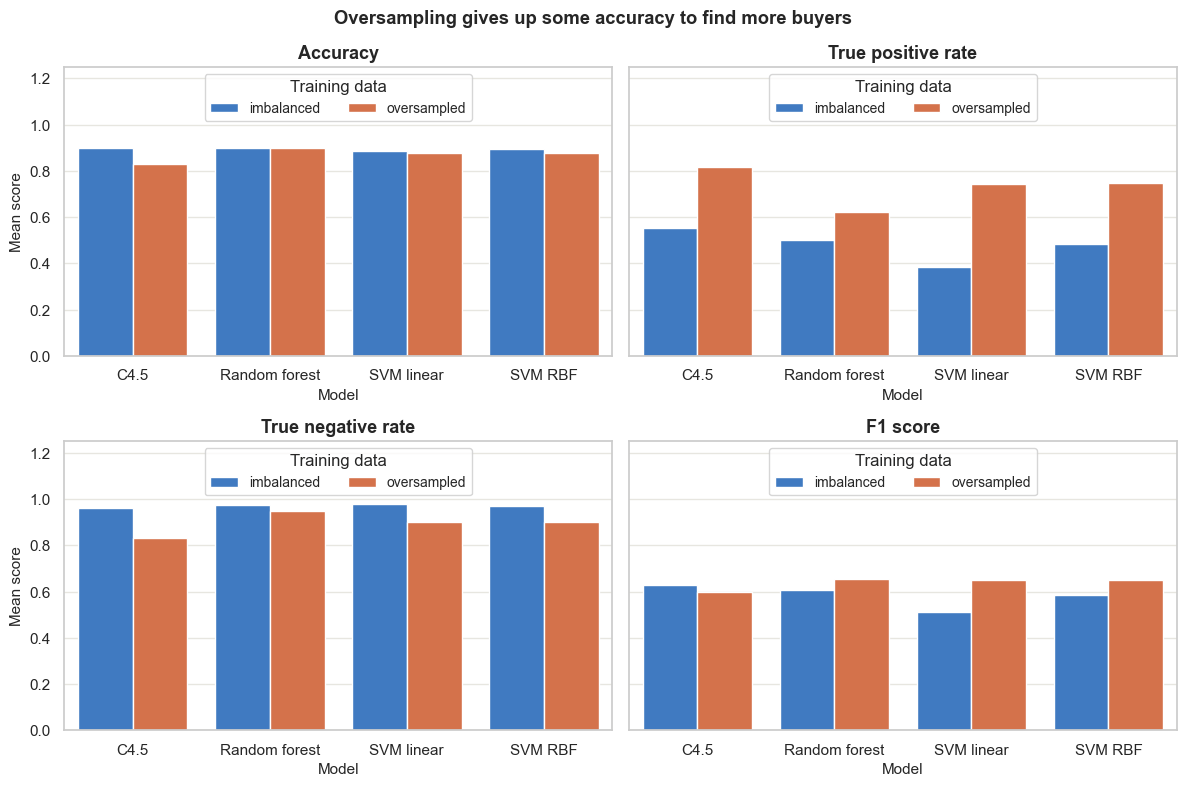

In [8]:
long = res.melt(id_vars=["model", "setting", "repeat"], value_vars=METRICS, var_name="metric")
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
titles = {"accuracy": "Accuracy", "tpr": "True positive rate", "tnr": "True negative rate", "f1": "F1 score"}
for ax, metric in zip(axes.ravel(), METRICS):
    part = long[long["metric"] == metric]
    sns.barplot(data=part, x="model", y="value", hue="setting", errorbar=None, ax=ax,
                palette=COLOURS[:2], hue_order=["imbalanced", "oversampled"])
    ax.set_title(titles[metric])
    ax.set_xlabel("Model")
    ax.set_ylabel("Mean score")
    ax.set_ylim(0, 1.25)
    ax.legend(title="Training data", loc="upper center", ncol=2)
fig.suptitle("Oversampling gives up some accuracy to find more buyers", fontweight="bold")
plt.tight_layout()
plt.show()

Oversampling finds many more buyers. TPR rises from 0.55 to 0.82 for C4.5, 0.39 to 0.74 for linear SVM, 0.48 to 0.75 for RBF SVM, and 0.50 to 0.62 for random forest. It costs some accuracy for most models, and C4.5 loses the most (89.91% to 83.10%).

## 9. Results at a glance
All of these use the oversampled setting and 10 repeats. Our accuracy and F1 are converted to a 50/50 test set, the basis the paper's figures appear to fit.

| Model | Accuracy % (ours) | Accuracy % (paper) | TPR (ours) | TPR (paper) | F1 (ours) | F1 (paper) |
|---|---|---|---|---|---|---|
| C4.5 | 82.57 | 82.34 | 0.82 | 0.79 | 0.82 | 0.82 |
| Random forest | 78.52 | 82.29 | 0.62 | 0.74 | 0.74 | 0.81 |
| SVM linear | 82.19 | 84.26 | 0.74 | 0.75 | 0.81 | 0.82 |
| SVM RBF | 82.37 | 84.88 | 0.75 | 0.75 | 0.81 | 0.82 |

We got very close to the paper for C4.5. Our two SVMs are about 2 to 3 points lower on accuracy, and random forest is about 4 points lower. Oversampling raised TPR for every model. C4.5 has the highest accuracy of these four here, while in the paper RBF SVM does. We are not sure why our C4.5 does relatively better, and it may be linked to our approximation of C4.5.

## 10. Key takeaways
We ran 10 repeats. Set N_REPEATS = 100 for final results.

Accuracy misleads on this data. Always answering "no purchase" gives 84.5%. On imbalanced data our models reach 88.54% to 89.95%, yet they find only 0.39 to 0.55 of the buyers.

Our imbalanced results are close to the paper, with RBF SVM as the largest gap (89.42% against 86.14%). Oversampling raises TPR for all models. On the 50/50 basis, which the paper's figures appear to fit, we are close for C4.5 and somewhat lower for the SVMs. Random forest is the clear gap.

Some significance results differ from the paper. RBF SVM beats C4.5 on natural-test accuracy, as in the paper, but they are about equal on the 50/50 basis. On imbalanced data, RBF SVM beats linear SVM, the opposite of the paper's Table 5.